# Лабораторная работа №4. MLOps

**Выполнил:** Ненашкин В. Д., АВТ-313.  
**Дисциплина:** «Системы искусственного интеллекта и машинное обучение».  
**Вариант 14:** прогноз прочности бетона на сжатие.

Цель — пройти весь цикл работы с моделью: подготовить данные, сравнить эксперименты в MLflow, зарегистрировать версии, запустить API в Docker, обновить модель и выполнить откат. В конце выполнены дополнительные задания: MLflow и обучение в контейнерах, сохранение данных в volume, автоматическая проверка API, контрольная сумма модели, нагрузка, журнал предсказаний и проверка распределений.

Ноутбук запускается сверху вниз из папки проекта. Нужны Python 3.12, пакеты из `requirements.txt` и работающий Docker с Compose. Порты 5001, 5002 и 8000 должны быть свободны. Все служебные файлы создаются в `runtime/`, они не входят в Git.

## 1. Подготовка данных

Используется **Concrete Compressive Strength**, автор I-Cheng Yeh, [UCI](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength), [DOI 10.24432/C5PK67](https://doi.org/10.24432/C5PK67). Лицензия данных — [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). `concrete.csv` получен из официального `Concrete_Data.xls`: изменены только заголовки и формат хранения чисел, строки не удалялись и не переставлялись.

Первые семь признаков — количества цемента, шлака, золы, воды, суперпластификатора, крупного и мелкого заполнителя в **кг/м³**; `age` — возраст в **днях**. Целевая `strength` — прочность в **МПа**.

In [1]:
import concurrent.futures
import contextlib
import hashlib
import json
import os
from pathlib import Path
import shutil
import signal
import socket
import subprocess
import sys
import tempfile
import time

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from mlflow import MlflowClient
from mlflow.models import infer_signature
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

runtime = Path('runtime')
runtime.mkdir(exist_ok=True)
features = ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age']
data = pd.read_csv('concrete.csv').astype(float)
data_sha = hashlib.sha256(Path('concrete.csv').read_bytes()).hexdigest()
assert data_sha == '3ab599b33547715db9c672788f3d3316b730fbca689a469afe2488f03b4a7a05'
assert list(data.columns) == features + ['strength']
assert np.isfinite(data.to_numpy()).all()
print('Размер:', data.shape, '| пропусков:', data.isna().sum().sum(), '| полных повторов:', data.duplicated().sum())
print('SHA-256:', data_sha)
display(data.head())

Matplotlib is building the font cache; this may take a moment.


Размер: (1030, 9) | пропусков: 0 | полных повторов: 25
SHA-256: 3ab599b33547715db9c672788f3d3316b730fbca689a469afe2488f03b4a7a05


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28.0,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28.0,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270.0,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365.0,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360.0,44.296075


В наборе 1030 строк, восемь признаков и целевая прочность. Пропусков нет, 25 полностью повторяющихся строк оставлены. Контрольная сумма позволяет проверить, что используется тот же CSV. Повторные наблюдения одной рецептуры будут храниться в одной части выборки.

### Разбиение без попадания одной рецептуры в разные части

Группа определяется семью компонентами, без возраста: одна смесь могла измеряться в разные дни. Сначала выделяется 20% групп в test, затем 25% оставшихся групп в validation. Seed 42 фиксирован. Test не участвует в выборе алгоритма или параметров.

In [2]:
groups = data[features[:-1]].apply(lambda row: '|'.join(format(value, '.17g') for value in row), axis=1)
trainval, test = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(data, groups=groups))
train_part, val_part = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42).split(data.iloc[trainval], groups=groups.iloc[trainval]))
split = {'train': sorted(trainval[train_part].tolist()), 'validation': sorted(trainval[val_part].tolist()), 'test': sorted(test.tolist())}
partitions = [set(split[name]) for name in split]
assert set.union(*partitions) == set(range(len(data)))
assert sum(map(len, partitions)) == len(data)
group_sets = [set(groups.iloc[split[name]]) for name in split]
assert all(not group_sets[i] & group_sets[j] for i in range(3) for j in range(i + 1, 3))
(runtime / 'split.json').write_text(json.dumps(split, indent=2))
split_sha = hashlib.sha256((runtime / 'split.json').read_bytes()).hexdigest()
X_train = data.iloc[split['train']][features]
y_train = data.iloc[split['train']]['strength']
X_val = data.iloc[split['validation']][features]
y_val = data.iloc[split['validation']]['strength']
display(pd.DataFrame({'Часть': list(split), 'Строки': [len(split[name]) for name in split], 'Рецептуры': [len(group) for group in group_sets]}))

,Часть,Строки,Рецептуры
0,train,628,256
1,validation,196,86
2,test,206,86


Получены 628 train, 196 validation и 206 test-строк; число рецептур — 256, 86 и 86. Пересечений нет. Доли строк отличаются от долей групп, поскольку у рецептур разное число измерений. Такое разбиение проверяет перенос на новые составы.

## 2. Учёт экспериментов в MLflow

Запустим локальный MLflow на порту 5001. SQLite хранит сведения о runs и Registry, отдельная папка — модели и другие артефакты. Сервер остаётся работающим до последней ячейки. На Mac порт 5000 может использоваться системными службами.

In [3]:
tracking = 'http://127.0.0.1:5001'
with socket.socket() as port:
    port.setsockopt(socket.SOL_SOCKET, socket.SO_REUSEADDR, 1)
    try:
        port.bind(('127.0.0.1', 5001))
    except OSError as error:
        raise RuntimeError('Порт 5001 занят. Остановите ранее запущенный MLflow и повторите ячейку.') from error
store = runtime / 'notebook-mlflow'
store.mkdir(exist_ok=True)
server_log = (runtime / 'mlflow.log').open('w')
server = subprocess.Popen([sys.executable, '-m', 'mlflow', 'server', '--backend-store-uri', f'sqlite:///{store}/mlflow.db', '--artifacts-destination', str(store / 'artifacts'), '--serve-artifacts', '--host', '127.0.0.1', '--port', '5001', '--workers', '1'], stdout=server_log, stderr=subprocess.STDOUT, start_new_session=True)
(runtime / 'mlflow.pid').write_text(str(server.pid))
for attempt in range(60):
    assert server.poll() is None, 'MLflow не запустился: смотрите runtime/mlflow.log'
    try:
        if requests.get(tracking + '/health', timeout=2).status_code == 200:
            break
    except requests.RequestException:
        pass
    time.sleep(1)
else:
    raise TimeoutError('MLflow не готов')
mlflow.set_tracking_uri(tracking)
mlflow.set_experiment('lab4-concrete')
client = MlflowClient()
print('MLflow:', tracking, '| health:', requests.get(tracking + '/health').text)

2026/11/10 13:17:39 INFO mlflow.tracking.fluent: Experiment with name 'lab4-concrete' does not exist. Creating a new experiment.


MLflow: http://127.0.0.1:5001 | health: OK


MLflow готов. **Experiment** объединяет запуски, **run** хранит один опыт, parameters описывают настройки, metrics — измеренные результаты, artifacts — файлы. В браузере можно открыть адрес выше и сравнить runs.

### Настройки до просмотра результатов

Для Ridge проверяются `alpha=0.1,1,10`. Для RandomForest — 50, 100 и 200 деревьев, глубины 3, 5 и без ограничения: всего 12 опытов. Масштабирование Ridge находится внутри Pipeline и обучается только на train.

Критерий — минимальная **validation MAE**. При равенстве в пределах `1e-9` предпочитается Ridge, затем больший alpha; для леса — меньшая глубина, затем меньше деревьев. RMSE и R² нужны для дополнительного сравнения, test для выбора не используется.

In [4]:
configs = [{'algorithm': 'Ridge', 'alpha': alpha} for alpha in [0.1, 1, 10]]
configs += [{'algorithm': 'RandomForest', 'trees': trees, 'depth': depth} for trees in [50, 100, 200] for depth in [3, 5, None]]
display(pd.DataFrame(configs).fillna('—'))

,algorithm,alpha,trees,depth
0,Ridge,0.1,—,—
1,Ridge,1.0,—,—
2,Ridge,10.0,—,—
3,RandomForest,—,50.0,3.0
4,RandomForest,—,50.0,5.0
5,RandomForest,—,50.0,—
6,RandomForest,—,100.0,3.0
7,RandomForest,—,100.0,5.0
8,RandomForest,—,100.0,—
9,RandomForest,—,200.0,3.0


Сетка задана заранее. Для всех моделей используются одни и те же данные и разбиение. При сравнении леса отдельно видно влияние глубины и числа деревьев.

### Обучение и сохранение результатов

Каждый run сохранит параметры, train/validation-метрики, модель целиком, схему входа и выхода (signature), пример входа, CSV, индексы разбиения, зависимости и этот ноутбук. Контрольные суммы связывают модель с конкретными данными. Подробные сообщения библиотек записываются в `runtime/training.log`.

In [5]:
results = []
with (runtime / 'training.log').open('w') as log, contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
    for config in configs:
        if config['algorithm'] == 'Ridge':
            model = Pipeline([('scaler', StandardScaler()), ('model', Ridge(alpha=config['alpha']))])
            complexity = (0, -config['alpha'], 0)
        else:
            model = Pipeline([('model', RandomForestRegressor(n_estimators=config['trees'], max_depth=config['depth'], random_state=42, n_jobs=1))])
            complexity = (1, config['depth'] if config['depth'] is not None else 10**6, config['trees'])
        name = f"Ridge_{config['alpha']}" if config['algorithm'] == 'Ridge' else f"RF_{config['trees']}_{config['depth']}"
        with mlflow.start_run(run_name=name) as run:
            mlflow.log_params({**config, 'seed': 42})
            mlflow.set_tags({'variant': '14', 'data_sha256': data_sha, 'split_sha256': split_sha})
            started = time.perf_counter()
            model.fit(X_train, y_train)
            seconds = time.perf_counter() - started
            predicted = model.predict(X_val)
            metrics = {'train_mae': mean_absolute_error(y_train, model.predict(X_train)), 'val_mae': mean_absolute_error(y_val, predicted), 'val_rmse': mean_squared_error(y_val, predicted)**0.5, 'val_r2': r2_score(y_val, predicted), 'training_seconds': seconds}
            mlflow.log_metrics(metrics)
            for filename in ['concrete.csv', 'requirements.txt', 'lab4.ipynb', str(runtime / 'split.json')]:
                mlflow.log_artifact(filename)
            mlflow.log_input(mlflow.data.from_pandas(X_train.assign(strength=y_train), targets='strength', name='concrete-train'), context='training')
            saved = mlflow.sklearn.log_model(model, name='model', signature=infer_signature(X_train, model.predict(X_train)), input_example=X_val.head(3), pip_requirements='requirements.txt')
            results.append({**config, **metrics, 'run_id': run.info.run_id, 'model_uri': saved.model_uri, 'complexity': complexity})
comparison = pd.DataFrame(results).sort_values('val_mae')
with pd.option_context('display.max_colwidth', 40, 'display.max_rows', 20):
    display(comparison[['algorithm', 'alpha', 'trees', 'depth', 'val_mae', 'val_rmse', 'val_r2', 'run_id']].fillna('—'))
print('Успешных опытов:', len(results))

,algorithm,alpha,trees,depth,val_mae,val_rmse,val_r2,run_id
5,RandomForest,—,50.0,—,4.527281,6.551017,0.842683,f7f9310681dd489cbc5ddb9032c6cb82
11,RandomForest,—,200.0,—,4.535338,6.518789,0.844227,49031d5d9d6f43b7a4d48491dee9de8d
8,RandomForest,—,100.0,—,4.546101,6.542341,0.843099,90788f25dbd24efeb4e3388d61e3d30f
4,RandomForest,—,50.0,5.0,5.256109,7.402351,0.799138,bc3324d49b2c4f4e9625a782f377cb29
10,RandomForest,—,200.0,5.0,5.259876,7.341148,0.802445,7a5fe04617214d25bc84b9ba99c79891
7,RandomForest,—,100.0,5.0,5.280842,7.420663,0.798143,e664e3e5f34642cfbe5c0408e5e7ce3f
3,RandomForest,—,50.0,3.0,6.661568,9.339637,0.680244,ca3c18f84ada4bebbdd5fa7afe6faf6c
6,RandomForest,—,100.0,3.0,6.669158,9.309480,0.682305,187b1a08708f4a6a96f48abd87b12341
9,RandomForest,—,200.0,3.0,6.698725,9.326673,0.681131,790e7ec0c2684d23948d003f02d17d0b
0,Ridge,0.1,—,—,8.403973,10.786462,0.573502,27ea03cd879c4f06aef86fb93fa4f61d


Успешных опытов: 12


Все 12 опытов завершены. В таблице приведены фактические метрики и run_id; У Ridge глубина и число деревьев не задаются; у RandomForest «—» в depth означает отсутствие ограничения глубины. Лес с полной глубиной заметно лучше Ridge. Большее число деревьев не обязательно уменьшает MAE на фиксированной validation-части.

## 3. Registry и выбор champion

Зарегистрируем лучший run Ridge и лучший run RandomForest, не обучая их повторно. Registry-версия указывает на уже сохранённую модель. Alias `champion` — изменяемая ссылка на выбранную версию.

In [6]:
best_by_algorithm = []
for algorithm in ['Ridge', 'RandomForest']:
    candidates = [row for row in results if row['algorithm'] == algorithm]
    minimum = min(row['val_mae'] for row in candidates)
    best = min([row for row in candidates if row['val_mae'] <= minimum + 1e-9], key=lambda row: row['complexity'])
    version = mlflow.register_model(best['model_uri'], 'concrete-strength')
    best_by_algorithm.append({**best, 'version': str(version.version)})
minimum = min(row['val_mae'] for row in best_by_algorithm)
champion = min([row for row in best_by_algorithm if row['val_mae'] <= minimum + 1e-9], key=lambda row: row['complexity'])
alternative = next(row for row in best_by_algorithm if row is not champion)
client.set_registered_model_alias('concrete-strength', 'champion', champion['version'])
display(pd.DataFrame(best_by_algorithm)[['algorithm', 'version', 'val_mae', 'run_id']])
print('Champion:', champion['algorithm'], '| версия:', champion['version'])

Successfully registered model 'concrete-strength'.
2026/11/10 13:17:45 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: concrete-strength, version 1


Created version '1' of model 'concrete-strength'.
Registered model 'concrete-strength' already exists. Creating a new version of this model...
2026/11/10 13:17:45 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: concrete-strength, version 2


Created version '2' of model 'concrete-strength'.


,algorithm,version,val_mae,run_id
0,Ridge,1,8.403973,27ea03cd879c4f06aef86fb93fa4f61d
1,RandomForest,2,4.527281,f7f9310681dd489cbc5ddb9032c6cb82


Champion: RandomForest | версия: 2


Champion выбран по validation MAE. Параметры победителя приведены в таблице сравнения выше; вторая версия нужна для демонстрации обновления и отката. Номера Registry берутся из ответа сервера: при повторении они могут увеличиться.

### Экспорт конкретной версии

Функция ниже один раз разрешает alias, скачивает **эту конкретную версию** и переносит весь MLflow-артефакт со signature. Она также сохраняет единицы признаков, происхождение модели и SHA-256 `model.pkl`. Три validation-объекта дают запрос и эталон ответа для проверки доставки; test здесь не используется.

In [7]:
def export_champion():
    version = client.get_model_version_by_alias('concrete-strength', 'champion')
    run = client.get_run(version.run_id)
    assert run.data.tags['data_sha256'] == data_sha
    assert run.data.tags['split_sha256'] == split_sha
    with tempfile.TemporaryDirectory(dir=runtime) as temporary:
        downloaded = mlflow.artifacts.download_artifacts(artifact_uri=f'models:/concrete-strength/{version.version}', dst_path=temporary)
        shutil.rmtree(runtime / 'model', ignore_errors=True)
        shutil.copytree(downloaded, runtime / 'model')
    model_sha = hashlib.sha256((runtime / 'model/model.pkl').read_bytes()).hexdigest()
    metadata = {'model_name': 'concrete-strength', 'model_version': str(version.version), 'run_id': version.run_id, 'feature_names': features, 'feature_units': {name: 'day' if name == 'age' else 'kg/m^3' for name in features}, 'target_unit': 'MPa', 'task': 'regression', 'model_sha256': model_sha, 'data_sha256': data_sha, 'split_sha256': split_sha}
    (runtime / 'model/metadata.json').write_text(json.dumps(metadata, indent=2))
    exported = mlflow.sklearn.load_model(str(runtime / 'model'))
    request = {'instances': X_val.head(3).to_dict(orient='records')}
    expected = {'predictions': exported.predict(X_val.head(3)).tolist(), 'model_version': str(version.version), 'model_sha256': model_sha}
    (runtime / 'request.json').write_text(json.dumps(request, indent=2))
    (runtime / 'expected.json').write_text(json.dumps(expected, indent=2))
    return metadata, request, expected

metadata, request, expected = export_champion()
print('Версия:', metadata['model_version'], '| SHA-256:', metadata['model_sha256'])
display(pd.DataFrame({'Предсказанная прочность, МПа': expected['predictions']}))

Версия: 2 | SHA-256: 1feecb579577ad321199e3ec5213ba12bb632bf1fdfdd4e24bd70f4ad0589dd9


,"Предсказанная прочность, МПа"
0,62.597871
1,49.465159
2,50.370400


В `runtime/model` теперь находится независимый снимок модели. Изменение alias на сервере не изменит этот каталог и уже собранный Docker-образ. SHA-256 помогает проверить, что доставлен тот же файл.

### Единственная итоговая оценка на test

Выбор алгоритма и параметров завершён. Теперь оцениваем champion на отложенных test-строках. Эти метрики нельзя использовать для нового подбора параметров в рамках того же сравнения.

In [8]:
X_test = data.iloc[split['test']][features]
y_test = data.iloc[split['test']]['strength']
exported = mlflow.sklearn.load_model(str(runtime / 'model'))
test_prediction = exported.predict(X_test)
test_metrics = {'MAE, МПа': mean_absolute_error(y_test, test_prediction), 'RMSE, МПа': mean_squared_error(y_test, test_prediction)**0.5, 'R²': r2_score(y_test, test_prediction)}
for name, value in zip(['test_mae', 'test_rmse', 'test_r2'], test_metrics.values()):
    client.log_metric(champion['run_id'], name, float(value))
display(pd.Series(test_metrics, name='Test, 206 строк').to_frame())

,"Test, 206 строк"
"MAE, МПа",4.640091
"RMSE, МПа",5.982299
R²,0.869437


Итоговая ошибка относится к новым рецептурам из test. MAE измеряет среднюю абсолютную ошибку в МПа; RMSE сильнее реагирует на большие промахи; R² сравнивает модель с прогнозом среднего. Доставка далее проверяется на validation-примерах, без повторного выбора по test.

## 4. API и Docker

`app.py` предоставляет `/health`, `/metadata`, `/docs` и `POST /predict`. Запрос содержит `instances` с восемью признаками, ответ — вещественные `predictions` в МПа, версию и время предсказания. Модель загружается один раз при старте; перепутанные, отсутствующие или некорректные поля дают 422.

Сначала выполним короткую встроенную проверку приложения, затем соберём образ v1. Все зависимости и модель входят в образ, API во время предсказания не нужен MLflow. Подробный вывод сборки останется в `runtime/build-v1.log`.

In [9]:
check = subprocess.run([sys.executable, 'app.py', '--check'], capture_output=True, text=True, check=True)
print(check.stdout.strip())
started = time.perf_counter()
with (runtime / 'build-v1.log').open('w') as log:
    subprocess.run(['docker', 'build', '-t', 'concrete-api:v1', '.'], stdout=log, stderr=subprocess.STDOUT, check=True)
build_v1_seconds = time.perf_counter() - started
image_v1 = json.loads(subprocess.check_output(['docker', 'image', 'inspect', 'concrete-api:v1']))[0]
print('v1:', image_v1['Id'])
print('Размер, МБ:', round(image_v1['Size'] / 1024**2, 1), '| сборка, с:', round(build_v1_seconds, 2))

OK: predictions, model version, SHA-256 and invalid request


v1: sha256:18b96c9d2467bc9416c82afe5bae0123ba0b2779ee913fc0c09310fb46a7f364
Размер, МБ: 1149.9 | сборка, с: 436.36


Приложение прошло проверку, образ собран. Размер и длительность выше измерены на этом компьютере; повторные сборки могут использовать кэш. Тег `v1` — имя Docker-образа, номер модели внутри него — отдельный Registry-идентификатор.

### Запуск и правильный запрос

Порт контейнера публикуется только на `127.0.0.1`. Дождёмся `/health`, отправим тот же пакет и сравним предсказания с экспортированной моделью.

In [10]:
container = 'concrete-lab4-notebook'
subprocess.run(['docker', 'run', '-d', '--name', container, '-p', '127.0.0.1:8000:8000', 'concrete-api:v1'], capture_output=True, check=True)
api = 'http://127.0.0.1:8000'
for attempt in range(60):
    try:
        if requests.get(api + '/health', timeout=2).status_code == 200:
            break
    except requests.RequestException:
        pass
    time.sleep(1)
health_v1 = requests.get(api + '/health', timeout=10).json()
response = requests.post(api + '/predict', json=request, timeout=10)
assert response.status_code == 200
answer = response.json()
np.testing.assert_allclose(answer['predictions'], expected['predictions'], rtol=1e-10, atol=1e-10)
assert str(answer['model_version']) == champion['version']
print('HTTP:', response.status_code, '| версия:', answer['model_version'])
display(pd.DataFrame({'Локальная модель': expected['predictions'], 'Контейнер': answer['predictions']}))

HTTP: 200 | версия: 2


,Локальная модель,Контейнер
0,62.597871,62.597871
1,49.465159,49.465159
2,50.370400,50.370400


Ответ контейнера совпал с локальным эталоном. Это проверка доставки, а не новая оценка качества модели. Готовность `/health` означает, что модель загрузилась, но ничего не говорит о её ошибке на новых данных.

### Ошибочные запросы

Проверим отсутствие и лишний признак, неправильный тип, пустой пакет, отрицательную величину и нулевой возраст. Корректный запрос из одного объекта также должен обрабатываться.

In [11]:
row = request['instances'][0]
bad_requests = {
    'Пустой пакет': {'instances': []},
    'Нет cement': {'instances': [{key: value for key, value in row.items() if key != 'cement'}]},
    'Лишний признак': {'instances': [{**row, 'unexpected': 1}]},
    'Строка вместо числа': {'instances': [{**row, 'cement': '100'}]},
    'Отрицательная вода': {'instances': [{**row, 'water': -1}]},
    'Нулевой возраст': {'instances': [{**row, 'age': 0}]},
}
checks = []
for case, payload in bad_requests.items():
    status = requests.post(api + '/predict', json=payload, timeout=10).status_code
    assert status == 422
    checks.append({'Запрос': case, 'HTTP': status})
single = requests.post(api + '/predict', json={'instances': [row]}, timeout=10)
assert single.status_code == 200
np.testing.assert_allclose(single.json()['predictions'], expected['predictions'][:1])
checks.append({'Запрос': 'Один корректный объект', 'HTTP': single.status_code})
display(pd.DataFrame(checks))

,Запрос,HTTP
0,Пустой пакет,422
1,Нет cement,422
2,Лишний признак,422
3,Строка вместо числа,422
4,Отрицательная вода,422
5,Нулевой возраст,422
6,Один корректный объект,200


Некорректный ввод отклонён с HTTP 422, правильный одиночный запрос выполнен. Поэтому ошибка пользователя не превращается в необработанный ответ 500.

## 5. Обновление и откат

Для демонстрации поменяем champion на вторую зарегистрированную модель, экспортируем её и соберём v2. Это техническая проверка обновления, а не утверждение, что Ridge стал точнее леса.

In [12]:
client.set_registered_model_alias('concrete-strength', 'champion', alternative['version'])
metadata_v2, request_v2, expected_v2 = export_champion()
started = time.perf_counter()
with (runtime / 'build-v2.log').open('w') as log:
    subprocess.run(['docker', 'build', '-t', 'concrete-api:v2', '.'], stdout=log, stderr=subprocess.STDOUT, check=True)
build_v2_seconds = time.perf_counter() - started
image_v2 = json.loads(subprocess.check_output(['docker', 'image', 'inspect', 'concrete-api:v2']))[0]
subprocess.run(['docker', 'rm', '-f', container], capture_output=True, check=True)
subprocess.run(['docker', 'run', '-d', '--name', container, '-p', '127.0.0.1:8000:8000', 'concrete-api:v2'], capture_output=True, check=True)
for attempt in range(60):
    try:
        if requests.get(api + '/health', timeout=2).status_code == 200:
            break
    except requests.RequestException:
        pass
    time.sleep(1)
answer_v2 = requests.post(api + '/predict', json=request_v2, timeout=10).json()
np.testing.assert_allclose(answer_v2['predictions'], expected_v2['predictions'], rtol=1e-10, atol=1e-10)
assert str(answer_v2['model_version']) == alternative['version']
print('Обновление:', champion['version'], '→', answer_v2['model_version'])
print('Образ v2:', image_v2['Id'], '| сборка, с:', round(build_v2_seconds, 2))

Обновление: 2 → 1
Образ v2: sha256:90ae23612997d231966ebd7ac4ef0bcdea56ab108a99115c6669a4d92e01e215 | сборка, с: 3.31


Контейнер использует вторую Registry-версию и даёт её предсказания. Новая модель попала внутрь нового образа. Одно изменение alias без экспорта, сборки и перезапуска не обновило бы работающий API.

### Возврат сохранённого v1 без пересборки

In [13]:
subprocess.run(['docker', 'rm', '-f', container], capture_output=True, check=True)
subprocess.run(['docker', 'run', '-d', '--name', container, '-p', '127.0.0.1:8000:8000', 'concrete-api:v1'], capture_output=True, check=True)
for attempt in range(60):
    try:
        if requests.get(api + '/health', timeout=2).status_code == 200:
            break
    except requests.RequestException:
        pass
    time.sleep(1)
rollback = requests.post(api + '/predict', json=request, timeout=10).json()
np.testing.assert_allclose(rollback['predictions'], expected['predictions'], rtol=1e-10, atol=1e-10)
assert str(rollback['model_version']) == champion['version']
rollback_image = subprocess.check_output(['docker', 'inspect', '--format', '{{.Image}}', container], text=True).strip()
assert rollback_image == image_v1['Id']
client.set_registered_model_alias('concrete-strength', 'champion', champion['version'])
metadata, request, expected = export_champion()
print('Откат к версии:', rollback['model_version'], '| image ID не изменился:', rollback_image == image_v1['Id'])
print('Повторная сборка v1 не выполнялась.')

Откат к версии: 2 | image ID не изменился: True
Повторная сборка v1 не выполнялась.


Откат вернул исходные предсказания и тот же image ID. Alias и локальный экспорт также возвращены к исходному champion, чтобы следующие проверки использовали согласованные данные.

## 6. Docker Compose

Тот же API можно запускать декларативно через `compose.yaml`. Compose задаёт порт, журнал и healthcheck. Используется отдельный тег `concrete-api:compose`, поэтому образы v1 и v2 остаются для повторной демонстрации.

In [14]:
subprocess.run(['docker', 'rm', '-f', container], capture_output=True, check=True)
with (runtime / 'compose.log').open('w') as log:
    subprocess.run(['docker', 'compose', 'up', '-d', '--build', '--wait', 'api'], env={**os.environ, 'API_IMAGE': 'concrete-api:compose'}, stdout=log, stderr=subprocess.STDOUT, check=True)
compose_status = subprocess.check_output(['docker', 'compose', 'ps', '--format', '{{.Service}}: {{.State}} / {{.Health}}'], text=True)
print(compose_status.strip())
compose_answer = requests.post(api + '/predict', json=request, timeout=10).json()
np.testing.assert_allclose(compose_answer['predictions'], expected['predictions'], rtol=1e-10, atol=1e-10)
print('Предсказания Compose совпадают с champion.')

api: running / healthy
Предсказания Compose совпадают с champion.


Compose запустил сервис с состоянием healthy, ответы совпали с моделью. Healthcheck проверяет доступность, а не качество регрессии. Далее этот контейнер используется для наблюдения за нагрузкой и журналом.

## 7. Нагрузка и журнал предсказаний

Отправим 100 одинаковых пакетов с четырьмя параллельными клиентами. Пять прогревочных запросов не входят в измерение. Сетевое время включает передачу, очередь и обработку; время модели берётся отдельно из ответа API.

In [15]:
for _ in range(5):
    requests.post(api + '/predict', json=request, timeout=10).raise_for_status()

def measure_request(index):
    started = time.perf_counter()
    response = requests.post(api + '/predict', json=request, timeout=10)
    elapsed = (time.perf_counter() - started) * 1000
    response.raise_for_status()
    result = response.json()
    return {'request': index, 'round_trip_ms': elapsed, 'prediction_ms': result['prediction_time_ms']}

started = time.perf_counter()
with concurrent.futures.ThreadPoolExecutor(max_workers=4) as pool:
    measurements = pd.DataFrame(pool.map(measure_request, range(100)))
load_seconds = time.perf_counter() - started
print('Успешных запросов:', len(measurements), '| запросов/с:', round(100 / load_seconds, 2))
display(measurements[['round_trip_ms', 'prediction_ms']].quantile([0.5, 0.95, 0.99]).rename(index={0.5: 'p50', 0.95: 'p95', 0.99: 'p99'}))

Успешных запросов: 100 | запросов/с: 255.02


,round_trip_ms,prediction_ms
p50,15.498958,7.402105
p95,19.010148,10.859042
p99,19.428311,11.795557


Измерения относятся к текущему компьютеру, трём объектам в запросе и четырём клиентам. Они не являются универсальной характеристикой Docker или модели. Высокая пропускная способность сама по себе не означает высокую точность.

### Наблюдение за сервисом

Сохраним журнал и посмотрим последние записи. Учебный журнал содержит числовые признаки публичного набора, предсказания, версию модели и время. Время нагрузки можно сопоставить с измерениями самого API.

In [16]:
subprocess.run(['docker', 'compose', 'cp', 'api:/app/logs/predictions.jsonl', str(runtime / 'predictions.jsonl')], capture_output=True, check=True)
records = [json.loads(line) for line in (runtime / 'predictions.jsonl').read_text().splitlines() if line.strip()]
print('Записей журнала:', len(records))
display(pd.DataFrame(records).tail(3))
container_id = subprocess.check_output(['docker', 'compose', 'ps', '-q', 'api'], text=True).strip()
print(subprocess.check_output(['docker', 'stats', '--no-stream', '--format', 'CPU={{.CPUPerc}} Memory={{.MemUsage}}', container_id], text=True).strip())

Записей журнала: 106


,timestamp_utc,instances,predictions,model_version,prediction_time_ms,target_unit,request_id,model_sha256
103,2026-11-10T09:25:25.630056+00:00,"[{'cement': 540.0, 'slag': 0.0, 'fly_ash': 0.0...","[62.59787077800001, 49.46515940512001, 50.3704...",2,8.012292,MPa,aaf27353-2a3c-4686-9c8d-fe7f9f90e326,1feecb579577ad321199e3ec5213ba12bb632bf1fdfdd4...
104,2026-11-10T09:25:25.631420+00:00,"[{'cement': 540.0, 'slag': 0.0, 'fly_ash': 0.0...","[62.59787077800001, 49.46515940512001, 50.3704...",2,8.092958,MPa,3c0189cc-457b-406b-a487-98e5c4bc4bd3,1feecb579577ad321199e3ec5213ba12bb632bf1fdfdd4...
105,2026-11-10T09:25:25.631730+00:00,"[{'cement': 540.0, 'slag': 0.0, 'fly_ash': 0.0...","[62.59787077800001, 49.46515940512001, 50.3704...",2,7.620417,MPa,a39f5428-4fc2-4632-945f-828fec92d8d6,1feecb579577ad321199e3ec5213ba12bb632bf1fdfdd4...


CPU=0.54% Memory=155.9MiB / 7.748GiB


Журнал фиксирует фактические успешные запросы. Повторения из нагрузочного теста зависимы и не представляют поток реальных клиентов. Поэтому изменения распределений ниже нужно интерпретировать как учебную диагностику.

## 8. Изменение распределений

Сравним признаки train с validation, затем со входами из журнала API. Для каждого признака применяется двухвыборочный KS-тест, поправка Бонферрони по восьми признакам, уровень 0,05. Целевая прочность не используется.

Отдельный сценарий **искусственный**: к cement и water validation добавлены два стандартных отклонения train. Это проверка чувствительности метода, а не обнаруженный производственный дрейф.

In [17]:
synthetic = X_val.copy()
for name in ['cement', 'water']:
    synthetic[name] += 2 * X_train[name].std(ddof=0)
journal = pd.DataFrame([row for record in records for row in record['instances']])[features]
drift_rows = []
for scenario, current in [('Validation', X_val), ('Журнал API', journal), ('СИНТЕТИЧЕСКИЙ сдвиг', synthetic)]:
    for name in features:
        ks = ks_2samp(X_train[name], current[name])
        corrected = min(1.0, ks.pvalue * len(features))
        drift_rows.append({'Сценарий': scenario, 'Признак': name, 'KS': ks.statistic, 'p с поправкой': corrected, 'Флаг': corrected < 0.05})
drift = pd.DataFrame(drift_rows)
display(drift)

,Сценарий,Признак,KS,p с поправкой,Флаг
0,Validation,cement,0.089692,1.000000e+00,False
1,Validation,slag,0.087677,1.000000e+00,False
2,Validation,fly_ash,0.071786,1.000000e+00,False
3,Validation,water,0.149422,1.770633e-02,True
4,Validation,superplasticizer,0.146009,2.404621e-02,True
5,Validation,coarse_aggregate,0.124431,1.411240e-01,False
6,Validation,fine_aggregate,0.158781,7.379704e-03,True
7,Validation,age,0.053003,1.000000e+00,False
8,Журнал API,cement,0.705414,4.637223e-101,True
9,Журнал API,slag,0.427813,2.361781e-34,True


Флаг означает различие распределений в данном сравнении. Он не доказывает ухудшение MAE: нужны новые истинные значения прочности. Рецептуры и повторные API-запросы могут зависеть друг от друга, поэтому p-value здесь служат учебными индикаторами.

### Визуальная проверка искусственного сдвига

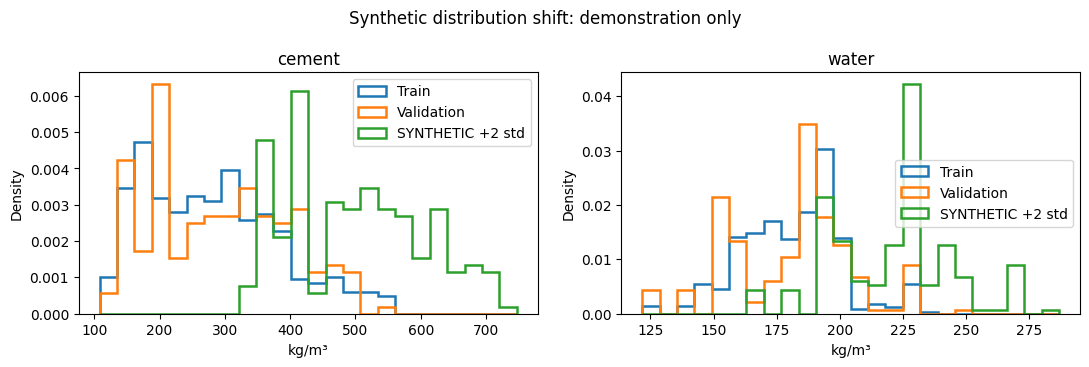

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
for ax, name in zip(axes, ['cement', 'water']):
    bins = np.linspace(min(X_train[name].min(), X_val[name].min()), synthetic[name].max(), 25)
    for frame, label in [(X_train, 'Train'), (X_val, 'Validation'), (synthetic, 'SYNTHETIC +2 std')]:
        ax.hist(frame[name], bins=bins, density=True, histtype='step', linewidth=1.8, label=label)
    ax.set(title=name, xlabel='kg/m³', ylabel='Density')
    ax.legend()
fig.suptitle('Synthetic distribution shift: demonstration only')
fig.tight_layout()
plt.show()

Искусственно изменённые распределения сдвинулись вправо. График позволяет проверить смысл статистического флага и отделить учебную имитацию от естественного различия train и validation.

## 9. MLflow и обучение в отдельных контейнерах

Дополнительные сервисы описаны в том же `compose.yaml`. MLflow доступен с хоста на порту 5002, внутри Compose-сети — `http://mlflow:5000`. Контейнер обучения выполняет один простой Ridge run по тем же train-индексам. Он не заменяет основной champion.

In [19]:
with (runtime / 'compose-mlflow.log').open('w') as log:
    subprocess.run(['docker', 'compose', '--profile', 'mlops', 'up', '-d', '--build', '--wait', 'mlflow'], stdout=log, stderr=subprocess.STDOUT, check=True)
    subprocess.run(['docker', 'compose', '--profile', 'mlops', 'run', '--rm', 'training'], stdout=log, stderr=subprocess.STDOUT, check=True)
extra_tracking = 'http://127.0.0.1:5002'
extra_client = MlflowClient(tracking_uri=extra_tracking)
extra_experiment = extra_client.get_experiment_by_name('lab4-container-training')
extra_runs = extra_client.search_runs([extra_experiment.experiment_id], filter_string="attributes.status = 'FINISHED'")
assert extra_runs
extra_run = extra_runs[0]
print('Контейнер обучения завершил run:', extra_run.info.run_id)
print('Метрики:', extra_run.data.metrics)
print('MLflow:', extra_tracking)

Контейнер обучения завершил run: 7723a7c4bdef4bdc8912f1b40283458f
Метрики: {'val_mae': 8.405001526912471}
MLflow: http://127.0.0.1:5002


Обучение прошло в отдельном контейнере и записало модель на MLflow по внутренней сети Compose. Named volume хранит SQLite и артефакты независимо от контейнера. Проверим не только список runs, но и сохранность самого файла модели.

### Пересоздание MLflow с сохранением volume

In [20]:
mlflow.set_tracking_uri(extra_tracking)
mlflow.set_registry_uri(extra_tracking)
extra_model_uri = extra_run.data.tags['model_uri']
with tempfile.TemporaryDirectory(dir=runtime) as temporary:
    downloaded = Path(mlflow.artifacts.download_artifacts(artifact_uri=extra_model_uri, dst_path=temporary))
    hash_before = hashlib.sha256((downloaded / 'model.pkl').read_bytes()).hexdigest()
with (runtime / 'compose-restart.log').open('w') as log:
    subprocess.run(['docker', 'compose', '--profile', 'mlops', 'down'], stdout=log, stderr=subprocess.STDOUT, check=True)
    subprocess.run(['docker', 'compose', '--profile', 'mlops', 'up', '-d', '--wait', 'mlflow'], stdout=log, stderr=subprocess.STDOUT, check=True)
restored_run = extra_client.get_run(extra_run.info.run_id)
assert restored_run.info.status == 'FINISHED'
with tempfile.TemporaryDirectory(dir=runtime) as temporary:
    downloaded = Path(mlflow.artifacts.download_artifacts(artifact_uri=extra_model_uri, dst_path=temporary))
    hash_after = hashlib.sha256((downloaded / 'model.pkl').read_bytes()).hexdigest()
assert hash_before == hash_after
mlflow.set_tracking_uri(tracking)
mlflow.set_registry_uri(tracking)
print('Run сохранён:', restored_run.info.run_id)
print('SHA-256 до и после совпал:', hash_before == hash_after)
print('SHA-256:', hash_after)

Run сохранён: 7723a7c4bdef4bdc8912f1b40283458f
SHA-256 до и после совпал: True
SHA-256: f0f90ab57ff7145702953e5b4f24bc1a474dd5cbaf202bf9378f72b64414a0f9


После `down` и нового `up` восстановились и run, и тот же файл модели. Это подтверждает работу persistent volume. Ключ `-v` здесь не используется: он удалил бы volume.

## 10. Итог и завершение

Соберём основные результаты в одной таблице и остановим созданные сервисы. Образы v1/v2, volumes и локальный каталог runtime сохраняются для повторного показа.

In [21]:
display(pd.DataFrame([
    {'Проверка': 'Эксперименты', 'Результат': f'{len(results)} успешных runs'},
    {'Проверка': 'Champion', 'Результат': f"{champion['algorithm']}, Registry {champion['version']}"},
    {'Проверка': 'Test MAE', 'Результат': f"{test_metrics['MAE, МПа']:.4f} МПа"},
    {'Проверка': 'v1 / v2 / откат', 'Результат': f"{champion['version']} → {alternative['version']} → {champion['version']}"},
    {'Проверка': 'Образы v1 / v2', 'Результат': f"{image_v1['Size']/1024**2:.1f} / {image_v2['Size']/1024**2:.1f} МБ"},
    {'Проверка': 'Нагрузка', 'Результат': f"100 успешных запросов, p95={measurements['round_trip_ms'].quantile(0.95):.2f} мс"},
    {'Проверка': 'Persistent volume', 'Результат': 'Run и SHA-256 модели сохранены'},
]))
with (runtime / 'shutdown.log').open('w') as log:
    subprocess.run(['docker', 'compose', '--profile', 'mlops', 'down'], stdout=log, stderr=subprocess.STDOUT, check=True)
os.killpg(server.pid, signal.SIGTERM)
server.wait(timeout=30)
server_log.close()
report = {'data_rows': len(data), 'recipe_count': groups.nunique(), 'split_rows': {name: len(indices) for name, indices in split.items()}, 'data_sha256': data_sha, 'experiments': results, 'registered': best_by_algorithm, 'champion': champion, 'test': test_metrics, 'metadata': metadata, 'images': {'v1': {'id': image_v1['Id'], 'size_bytes': image_v1['Size'], 'build_seconds': build_v1_seconds}, 'v2': {'id': image_v2['Id'], 'size_bytes': image_v2['Size'], 'build_seconds': build_v2_seconds}}, 'api_checks': checks, 'load': {'requests': 100, 'successful': len(measurements), 'requests_per_second': 100/load_seconds, 'p50_ms': measurements['round_trip_ms'].quantile(0.5), 'p95_ms': measurements['round_trip_ms'].quantile(0.95)}, 'journal_records': len(records), 'drift': drift.to_dict(orient='records'), 'persistence': {'run_id': restored_run.info.run_id, 'sha_before': hash_before, 'sha_after': hash_after}}
(runtime / 'result.json').write_text(json.dumps(report, indent=2, ensure_ascii=False))
print('Сервисы остановлены, данные и образы сохранены.')

,Проверка,Результат
0,Эксперименты,12 успешных runs
1,Champion,"RandomForest, Registry 2"
2,Test MAE,4.6401 МПа
3,v1 / v2 / откат,2 → 1 → 2
4,Образы v1 / v2,1149.9 / 1144.8 МБ
5,Нагрузка,"100 успешных запросов, p95=19.01 мс"
6,Persistent volume,Run и SHA-256 модели сохранены


Сервисы остановлены, данные и образы сохранены.


**Вывод.** Построен воспроизводимый цикл MLOps для регрессии прочности бетона. Модели сравнивались на одинаковой validation-части, выбранный champion оценён на test после выбора. Registry, run_id, версия модели и Docker image ID имеют разный смысл. Контейнер выдаёт те же предсказания, контролирует неправильный ввод и возвращается к прежней версии без пересборки. Дополнительно проверены нагрузка, журнал, изменение распределений и сохранность MLflow после пересоздания контейнера.

Размер образа и задержки относятся к измеренному запуску; используемые кэш и архитектура компьютера влияют на них. Проверка распределений не заменяет проверку качества на новых размеченных данных.

## Проверка в интерфейсах

Снимки показывают выполненные эксперименты, две Registry-версии и ответы API на корректный и некорректный запросы.

Сравнение экспериментов MLflow.

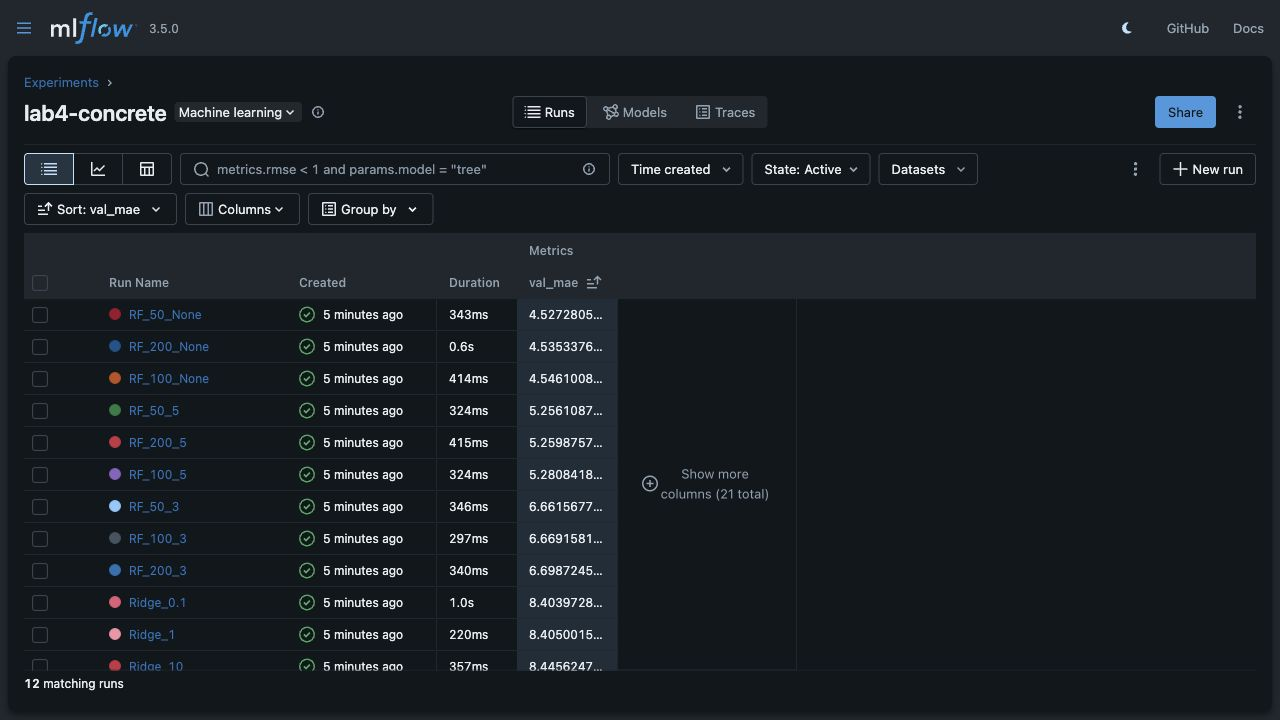

Registry и alias champion.

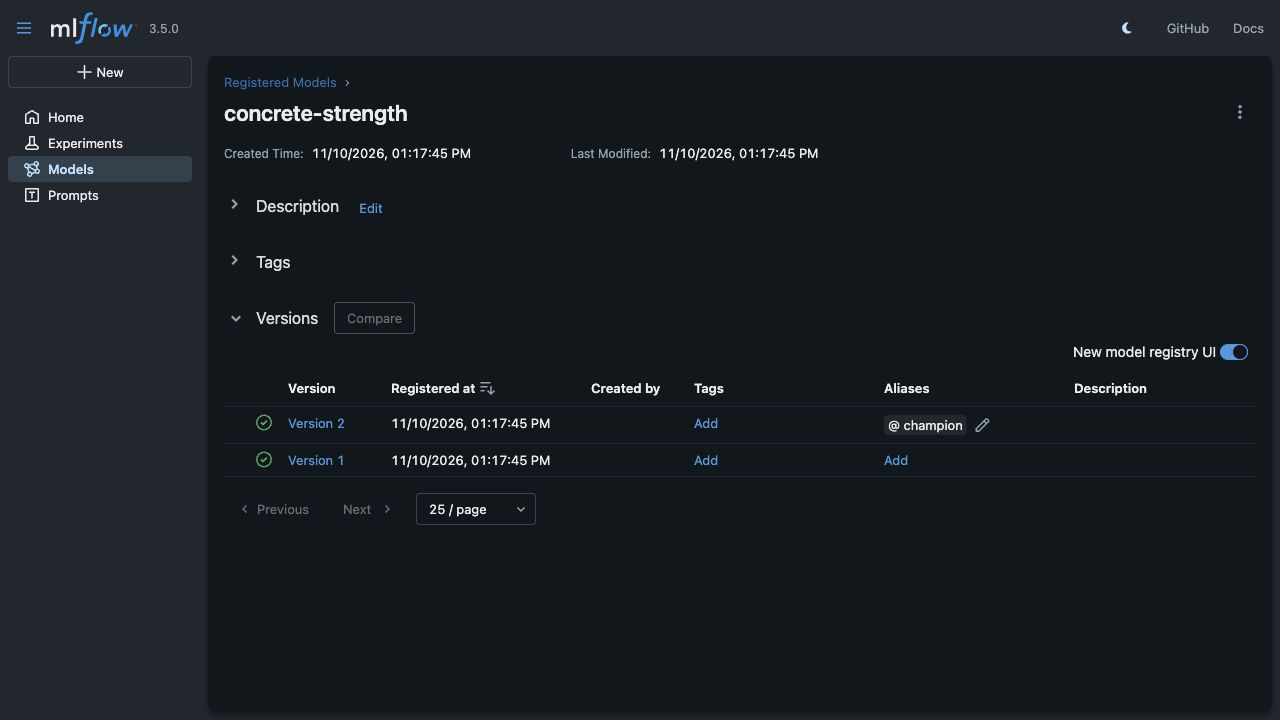

Успешный запрос API.

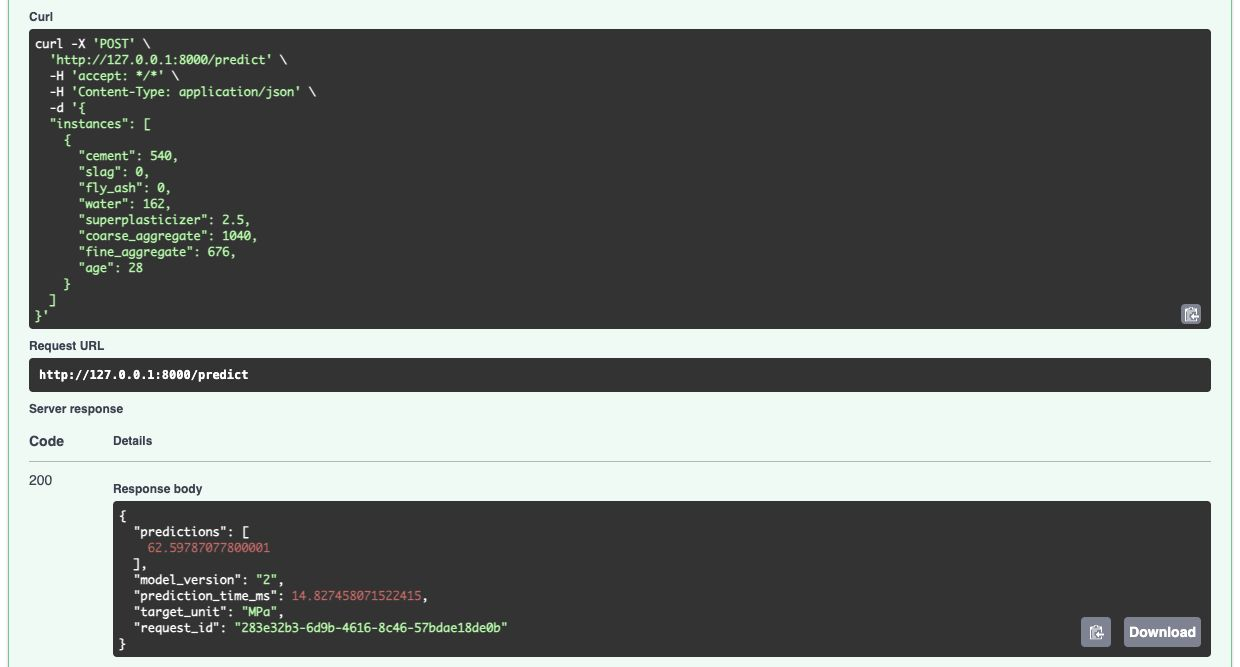

Отклонение некорректного запроса.

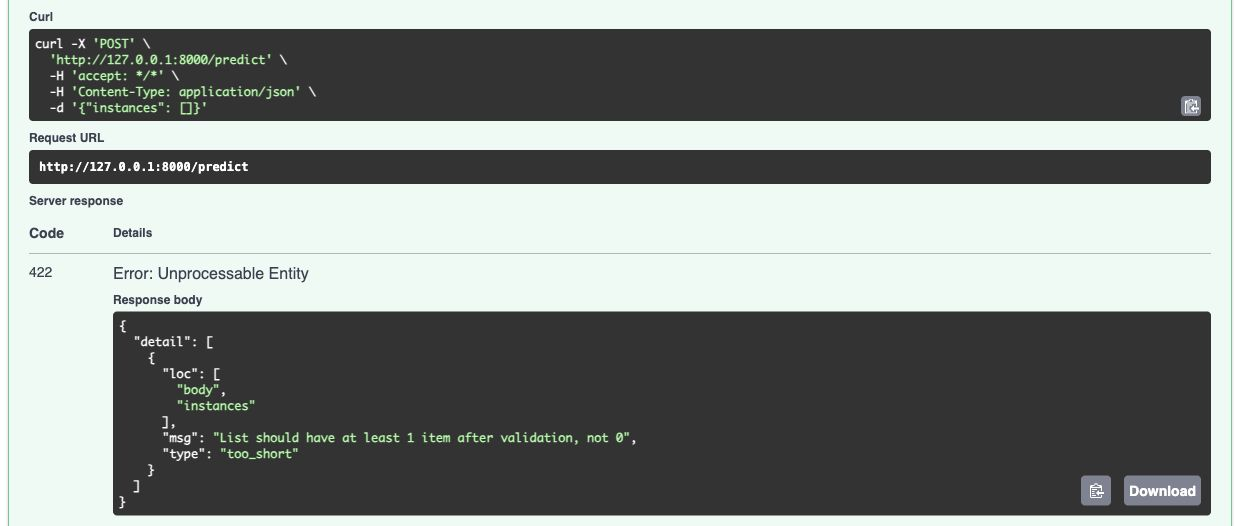

## Источники

1. Лабораторная работа 4. MLOps : методические указания // Системы искусственного интеллекта и машинное обучение : электронный курс НГТУ. – 2026. – URL: https://dispace.nstu.ru/course/965/33535/84296 (дата обращения: 10.11.2026).

2. Docker Compose : документация. – URL: https://docs.docker.com/compose/ (дата обращения: 10.11.2026).

3. FastAPI : документация. – URL: https://fastapi.tiangolo.com/ (дата обращения: 10.11.2026).

4. MLflow. Model Registry : документация. – URL: https://mlflow.org/docs/latest/ml/model-registry/ (дата обращения: 10.11.2026).

5. MLflow. Tracking : документация. – URL: https://mlflow.org/docs/latest/ml/tracking/ (дата обращения: 10.11.2026).

6. scikit-learn: machine learning in Python : документация. Common pitfalls and recommended practices. – URL: https://scikit-learn.org/stable/common_pitfalls.html (дата обращения: 10.11.2026).

7. Yeh I. Concrete Compressive Strength : набор данных // UCI Machine Learning Repository. – 1998. – DOI: 10.24432/C5PK67. – URL: https://doi.org/10.24432/C5PK67 (дата обращения: 10.11.2026).